# 01. Checkout de e-commerce: a decisão por trás do teste A/B

**A decisão:** a engenharia entregou um checkout de 1 clique. Antes de expor 100%
da base, precisamos responder a uma pergunta de negócio, não de código: ele
aumenta a receita por usuário o suficiente para justificar o lançamento? Errar
para qualquer lado custa. Lançar um efeito que não existe degrada a experiência
sem retorno; engavetar um ganho real deixa dinheiro na mesa.

Este capítulo não é sobre "rodar um teste". É sobre a disciplina que separa uma
leitura confiável de uma miragem estatística: planejar o tamanho da amostra antes
de coletar, blindar a alocação com um SRM, estimar o efeito por três lentes e
reduzir a variância com CUPED. E, o que um cientista sênior de fato faz, vamos
**quebrar o teste de propósito**: ver o que acontece quando a amostra é pequena
demais e quando a tentação de "olhar o resultado todo dia" aparece. No fim, você
não vai só saber chamar as funções: vai saber por que cada passo existe e onde a
`skxperiments` (ainda uma lib em desenvolvimento) para de te ajudar.

Base teórica: [II. Fundamentos](../../../docs/pt-br/teoria/01-fundamentos.md),
[IV. Inferência](../../../docs/pt-br/teoria/04-inferencia.md) (tópicos 14, 15, 17),
[III. Estimação](../../../docs/pt-br/teoria/03-estimacao.md) (tópico 11, CUPED) e
[V. Diagnósticos](../../../docs/pt-br/teoria/05-diagnosticos.md) (SRM).


## O reflexo natural (e por que ele não basta)

Você domina `pandas` e `statsmodels`. O instinto é direto: separar tratamento e
controle, rodar `scipy.stats.ttest_ind` na receita e lançar se `p < 0,05`.

O detalhe sutil: como a atribuição foi **randomizada**, esse t-test nem é
enviesado. O problema não é o estimador, é o **processo** em volta dele. Quatro
perguntas que o t-test sozinho não responde e que decidem se sua conclusão vale
algo:

1. **Você tinha poder?** Se a amostra era pequena para o efeito buscado, um
   `p > 0,05` não significa "não funciona". Significa "não sei".
2. **A alocação é confiável?** Um bug de logging ou um redirect que derruba mobile
   quebra o 50/50. Se a randomização falhou, nenhum número depois dela presta. É o
   que o SRM pega.
3. **Qual efeito você mede?** O efeito nesta amostra (população finita) ou na
   população de onde ela veio (superpopulação)? Perguntas diferentes, intervalos
   diferentes.
4. **Você vai olhar quantas vezes?** Espiar todo dia e parar no primeiro `p < 0,05`
   infla o falso-positivo em silêncio. É o erro mais comum e mais caro de testes
   online.

O capítulo responde às quatro. Segure a quarta: é exatamente onde a `skxperiments`
v1 tem um limite, e vamos ser francos sobre ele.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


def _find_data():
    """Locate examples/use_cases/data whether run from the notebook or the root."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base / "data", base / "examples" / "use_cases" / "data"):
            if (cand / "ecommerce_checkout.csv").exists():
                return cand
    raise FileNotFoundError("Could not locate examples/use_cases/data")


DATA = _find_data()

df = pd.read_csv(DATA / "ecommerce_checkout.csv")
print(df.shape)
df.head()

(4000, 6)


,user_id,device,sessions_pre,spend_pre,revenue_y0,revenue_y1
0,1,desktop,4,111.07,45.08,47.58
1,2,mobile,6,60.07,11.65,14.15
2,3,desktop,7,151.77,56.31,58.81
3,4,mobile,4,114.40,31.08,33.58
4,5,mobile,5,7.75,0.00,2.50


## 1. Planejar antes de coletar: quanto poder?

Poder é a probabilidade de detectar um efeito que existe de verdade. Baixo poder é
a armadilha silenciosa: você roda o teste, vê `p > 0,05` e conclui "não funciona",
quando a amostra nunca teve chance de enxergar o efeito.

A receita por usuário tem cauda longa (poucos gastam muito), então sua variância é
alta e o poder custa caro. Usamos o desvio padrão histórico (`revenue_y0`, o
comportamento sem tratamento) para dimensionar o teste para um efeito mínimo
detectável (MDE) de `+2,5`, com poder 80% e `alpha = 0,05`. O número que sai daqui
é um **compromisso**: é o `n` que vamos respeitar até o fim, não importa a
ansiedade no meio do caminho.


In [2]:
from skxperiments.design.power import power_analysis

std_hist = float(df["revenue_y0"].std())
plan = power_analysis(mde=2.5, power=0.8, std=std_hist, alpha=0.05)
print(f"historical std: {std_hist:.1f}")
print(f"required n_total: {plan.n_total}  (~{plan.n_treated} per arm)")
print(f"we collected {len(df)} users, comfortably above the plan")

historical std: 20.7
required n_total: 2151  (~1076 per arm)
we collected 4000 users, comfortably above the plan


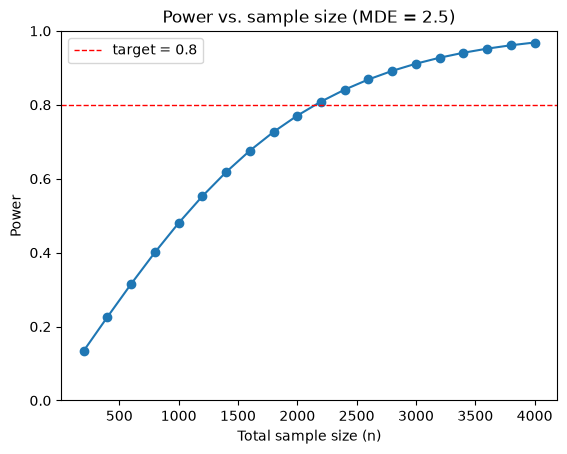

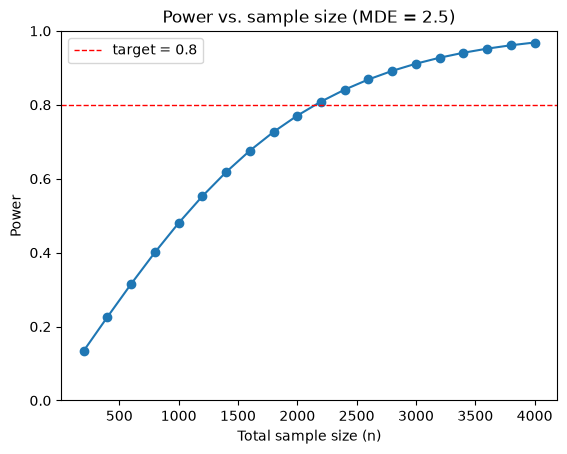

In [3]:
from skxperiments.reporting import plot_power_curve

n_values = list(range(200, 4001, 200))
ax = plot_power_curve(n_values, mde=2.5, std=std_hist, alpha=0.05)
ax.set_title("Power vs. sample size (MDE = 2.5)")
ax.figure

## 2. Desenhar e checar a alocação (SRM) antes de olhar o efeito

Randomizamos 50/50 com `CRD` e revelamos o resultado observado pela "tabela da
ciência": cada usuário mostra `revenue_y1` se caiu no tratamento, `revenue_y0`
caso contrário. Empacotamos esse passo num helper `observe()` para reusar
exatamente o mesmo procedimento em subamostras mais adiante.

Antes de estimar qualquer coisa, rodamos o `SRMTest`. SRM (sample ratio mismatch)
compara a proporção observada entre braços com a planejada. Se um bug de logging,
um redirect que derruba mobile ou um filtro de bot quebrou o 50/50, o SRM acende o
alerta, e aí nenhum número depois dele vale. Confiança na alocação vem antes da
verdade sobre o efeito.


In [4]:
from skxperiments.core.assignment import CRDAssignment
from skxperiments.design.crd import CRD
from skxperiments.diagnostics import SRMTest


def observe(frame, seed):
    """Randomize `frame` 50/50 and reveal the observed revenue (the science table).

    Each unit shows revenue_y1 if assigned to treatment, revenue_y0 otherwise.
    Returns a CRDAssignment ready for estimation. We wrap it so we can reuse the
    exact same procedure on subsamples later.
    """
    design = CRD(p=0.5, seed=seed)
    a = design.randomize(frame[["device", "sessions_pre", "spend_pre"]].copy())
    t = a.data_[a.treatment_col_].to_numpy()
    data = a.data_.copy()
    data["revenue"] = np.where(t == 1, frame["revenue_y1"].to_numpy(), frame["revenue_y0"].to_numpy())
    return CRDAssignment(data=data, treatment_col=a.treatment_col_, design=design, seed=seed)


assignment = observe(df, seed=101)
srm = SRMTest().run(assignment)
print(f"SRM flagged: {srm.flagged}  (p={srm.p_value:.3f})")

SRM flagged: False  (p=1.000)


## 3. Estimar o efeito por três lentes

Um número de efeito não basta; a lente importa.

- **`DifferenceInMeans` + `NeymanCI`** dá o efeito **nesta amostra** (SATE,
  população finita): "para estes 4000 usuários, qual foi o efeito?". O intervalo de
  Neyman é conservador por construção.
- **`BootstrapCI`** dá o efeito na **população de onde a amostra veio** (PATE,
  superpopulação), reamostrando dentro de cada braço. É a pergunta certa quando
  você quer generalizar para os próximos usuários.
- **`CUPED`** usa o gasto pré-experimento (`spend_pre`), correlacionado com a
  receita (rho aprox 0,6), para remover ruído que nada tem a ver com o tratamento.
  Ele regride a receita no pré-período e analisa o resíduo: o ponto continua sem
  viés, mas o erro padrão cai. É poder de graça, sem coletar um usuário a mais.


In [5]:
from skxperiments.estimators.difference_in_means import DifferenceInMeans
from skxperiments.estimators.cuped import CUPED
from skxperiments.inference import NeymanCI, BootstrapCI

neyman = NeymanCI(estimator=DifferenceInMeans(outcome_col="revenue")).fit(assignment).estimate()
boot = BootstrapCI(
    estimator=DifferenceInMeans(outcome_col="revenue"), n_resamples=1000, seed=0
).fit(assignment).estimate()
cuped = BootstrapCI(
    estimator=CUPED(outcome_col="revenue", pre_experiment_col="spend_pre"),
    n_resamples=1000, seed=0,
).fit(assignment).estimate()

pd.DataFrame([
    {"method": "DIM / Neyman (SATE)", "ATE": neyman.ate, "SE": neyman.se,
     "CI_low": neyman.ci[0], "CI_high": neyman.ci[1]},
    {"method": "DIM / Bootstrap (PATE)", "ATE": boot.ate, "SE": boot.se,
     "CI_low": boot.ci[0], "CI_high": boot.ci[1]},
    {"method": "CUPED / Bootstrap", "ATE": cuped.ate, "SE": cuped.se,
     "CI_low": cuped.ci[0], "CI_high": cuped.ci[1]},
]).round(3)

,method,ATE,SE,CI_low,CI_high
0,DIM / Neyman (SATE),2.910,0.654,1.627,4.192
1,DIM / Bootstrap (PATE),2.910,0.671,1.683,4.317
2,CUPED / Bootstrap,2.691,0.500,1.787,3.745


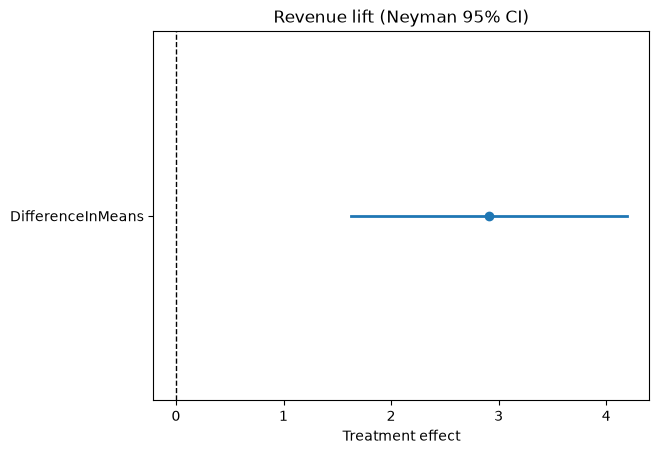

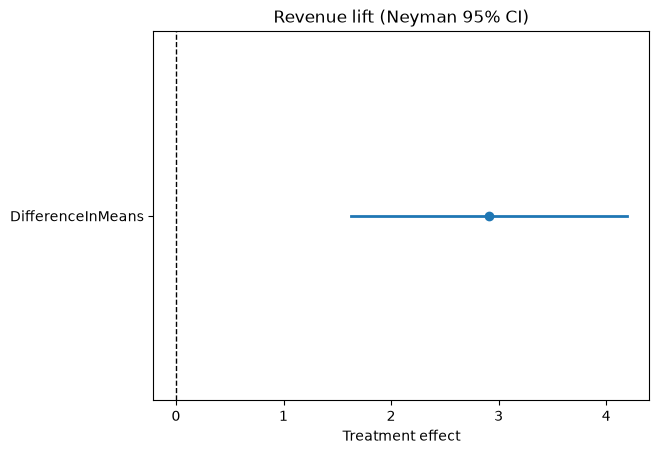

In [6]:
from skxperiments.reporting import plot_effect

ax = plot_effect(neyman)
ax.set_title("Revenue lift (Neyman 95% CI)")
ax.figure

## 4. Quebrando o teste, parte 1: a leitura precoce

Até aqui, tudo funcionou porque tínhamos 4000 usuários. E se você olhar cedo, com
só os primeiros 400? O ponto estimado ainda fica perto de `+2,5`, mas o intervalo
**atravessa o zero**: você não consegue descartar "efeito nulo". O CUPED aperta o
intervalo (menor erro padrão), mas não o suficiente para cruzar a linha.

A leitura honesta de um `p > 0,05` aqui não é "o checkout não funciona". É "com
400 usuários, eu não sei". Ausência de evidência não é evidência de ausência. E é
exatamente por isso que planejamos o `n` lá no começo: a disciplina é esperar a
amostra combinada, não apressar a conclusão.


In [7]:
early = df.head(400).reset_index(drop=True)   # an early read: the first 400 users
a_early = observe(early, seed=7)

dim_early = NeymanCI(estimator=DifferenceInMeans(outcome_col="revenue")).fit(a_early).estimate()
cuped_early = BootstrapCI(
    estimator=CUPED(outcome_col="revenue", pre_experiment_col="spend_pre"),
    n_resamples=1000, seed=0,
).fit(a_early).estimate()


def read_row(label, r):
    return {"read": label, "ATE": r.ate, "SE": r.se, "CI_low": r.ci[0],
            "CI_high": r.ci[1], "covers_0": bool(r.ci[0] <= 0 <= r.ci[1])}


pd.DataFrame([
    read_row("Early n=400 - DIM/Neyman", dim_early),
    read_row("Early n=400 - CUPED/Boot", cuped_early),
    read_row("Full n=4000 - CUPED/Boot", cuped),
]).round(3)

,read,ATE,SE,CI_low,CI_high,covers_0
0,Early n=400 - DIM/Neyman,2.253,2.037,-1.739,6.244,True
1,Early n=400 - CUPED/Boot,2.764,1.561,-0.284,5.826,True
2,Full n=4000 - CUPED/Boot,2.691,0.500,1.787,3.745,False


## 5. Quebrando o teste, parte 2: a tentação de espiar

"Se 400 não bastam, deixa eu ir olhando conforme os dados chegam e paro quando der
significativo." Essa é a armadilha mais cara de testes online. Todo teste da
`skxperiments` (Neyman, bootstrap, randomização) é de **horizonte fixo**: o
p-valor pressupõe que você olha **uma vez**, no `n` planejado. Cada olhada extra é
uma nova chance de cruzar a linha por acaso.

Para ver o tamanho do estrago, simulamos um A/A (sem efeito nenhum) e deixamos um
"espião" olhar em 5 momentos, parando na primeira vitória:


In [8]:
def run_peeking_sim(n_sims, looks, sd, rng):
    """A/A simulation (no true effect). Returns the cumulative false-positive rate
    by number of interim looks (a peeker stopping at the first win) and the
    single-look, fixed-horizon rate."""
    z_crit = 1.959963984540054  # two-sided 5%
    n_max = looks[-1]
    ever = np.zeros(len(looks))
    fixed = 0
    for _ in range(n_sims):
        y = rng.normal(0.0, sd, size=n_max)          # both arms share one no-effect law
        arm = rng.integers(0, 2, size=n_max)
        rejected = []
        for n in looks:
            a = arm[:n]
            yt, yc = y[:n][a == 1], y[:n][a == 0]
            se = np.sqrt(yt.var(ddof=1) / len(yt) + yc.var(ddof=1) / len(yc))
            rejected.append(abs((yt.mean() - yc.mean()) / se) > z_crit)
        ever += np.logical_or.accumulate(rejected)
        fixed += rejected[-1]
    return ever / n_sims, fixed / n_sims


looks = [400, 800, 1200, 1600, 2000]
cum_fpr, fixed_fpr = run_peeking_sim(1000, looks, std_hist, np.random.default_rng(2024))
print(f"Fixed horizon (one look at n={looks[-1]}): false-positive rate = {fixed_fpr:.1%}")
print(f"Peeking at {len(looks)} interim looks, stop at first win:  {cum_fpr[-1]:.1%}")
print("Nominal alpha = 5.0%")

Fixed horizon (one look at n=2000): false-positive rate = 5.0%
Peeking at 5 interim looks, stop at first win:  14.1%
Nominal alpha = 5.0%


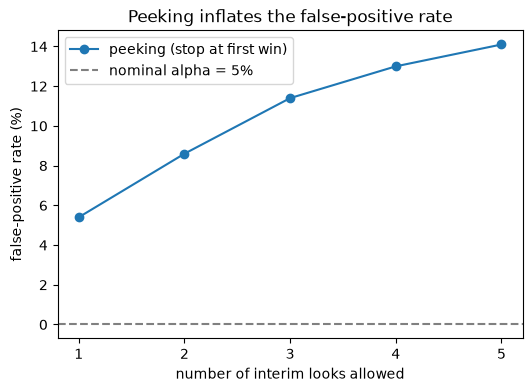

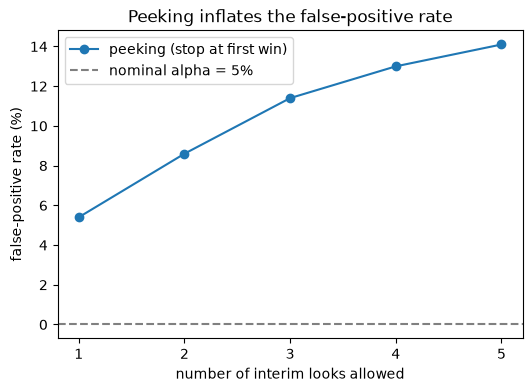

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(looks) + 1), cum_fpr * 100, marker="o", label="peeking (stop at first win)")
ax.axhline(0, ls="--", color="gray", label="nominal alpha = 5%")
ax.set_xlabel("number of interim looks allowed")
ax.set_ylabel("false-positive rate (%)")
ax.set_title("Peeking inflates the false-positive rate")
ax.set_xticks(range(1, len(looks) + 1))
ax.legend()
fig

### O limite honesto da lib (e o que usar no lugar)

Com uma olhada, o falso-positivo fica nos ~5% nominais. Com cinco olhadas parando
na primeira vitória, sobe para ~14%: quase o triplo do que você acha que está
controlando. A `skxperiments` v1 **não tem** teste sequencial nem inferência
sempre-válida (anytime-valid) para te proteger disso. Ser honesto sobre isso é
parte do trabalho.

O que fazer, então:

- **A opção disciplinada (funciona hoje):** pré-comprometa o horizonte na análise
  de poder e **não pare cedo** com base numa espiada. Foi para isso que
  dimensionamos o `n`.
- **Se o negócio exige monitorar continuamente:** você precisa de métodos feitos
  para isso, hoje fora da `skxperiments`. Duas famílias: *group-sequential* com
  gasto de alfa (O'Brien-Fleming, Pocock), quando há um `n` máximo e olhadas
  pré-planejadas; e *anytime-valid* / sequências de confiança (mSPRT, e-values),
  quando você quer poder parar a qualquer momento. Está no roadmap para a v2.

Essa é a lição que um cientista sênior passa e um tutorial de API esconde: saber
onde a ferramenta para de te cobrir.


## 6. Sensibilidade: o CUPED vale a pena em qualquer tamanho?

Uma última checagem antes de decidir: o ganho do CUPED não foi sorte de um `n`.
Repetindo a estimativa em tamanhos crescentes, o erro padrão do CUPED fica
consistentemente ~20 a 28% abaixo do difference-in-means. É uma redução
estrutural, vinda da correlação entre `spend_pre` e a receita, não um artefato da
amostra.


In [10]:
rows = []
for n in [250, 500, 1000, 2000, 4000]:
    a = observe(df.head(n).reset_index(drop=True), seed=101)
    se_dim = NeymanCI(estimator=DifferenceInMeans(outcome_col="revenue")).fit(a).estimate().se
    se_cuped = BootstrapCI(
        estimator=CUPED(outcome_col="revenue", pre_experiment_col="spend_pre"),
        n_resamples=500, seed=0,
    ).fit(a).estimate().se
    rows.append({"n": n, "SE_DIM": se_dim, "SE_CUPED": se_cuped,
                 "reduction_%": 100 * (1 - se_cuped / se_dim)})
pd.DataFrame(rows).round(2)

,n,SE_DIM,SE_CUPED,reduction_%
0,250,2.36,1.84,22.19
1,500,1.78,1.39,21.81
2,1000,1.29,0.92,28.17
3,2000,0.93,0.68,26.32
4,4000,0.65,0.50,23.04


## Decisão

Na amostra completa, as três lentes concordam: o efeito é positivo, perto do
`+2,5` verdadeiro (que aqui conhecemos só porque o dado é sintético; na vida real
não há gabarito), e o intervalo do CUPED, o mais estreito, exclui o zero com
folga. A recomendação é **lançar** o checkout de 1 clique.

Mas a decisão de negócio vem com o processo, não só com o número:

- **Respeite o horizonte.** O `n` do poder é um compromisso; não pare no primeiro
  pico verde.
- **SRM como guardião permanente.** Rode antes de qualquer leitura, sempre.
- **CUPED como padrão.** É precisão de graça quando existe uma covariável
  pré-período correlacionada.
- **Se precisar monitorar em tempo real,** use um método sequencial dedicado até a
  `skxperiments` ganhar o seu.

### Limites deste capítulo

- **Horizonte fixo.** Toda a inferência aqui assume uma leitura única no `n`
  planejado (ver a parte 2 acima).
- **SUTVA / unidade independente.** Tratamos cada usuário como isolado; se houvesse
  efeito de rede (um usuário influenciando outro), o desenho precisaria mudar.
- **Uma métrica primária.** Na prática, um lançamento mexe em várias métricas e
  guardrails ao mesmo tempo; isso é o
  [05. Muitas métricas](05_streaming_many_metrics.ipynb).
- **Gabarito sintético.** Conhecer o efeito verdadeiro é um recurso didático, não
  uma validação real da lib.

Próximo passo natural: [02. Lojas com blocagem](02_fashion_stores_blocking.ipynb).
